# FinanceBench RAG — Notebook 03a: LLM Query Rewriting (the extension)

**Where we are.** Notebook 02 found that plain dense search (bge-small, 256-word chunks) beat hybrid search and the reranker, and that the weak spot is **analyst-style questions**:

| Question type | Dense Recall@5 |
|---|---|
| metrics-generated | 0.80 |
| novel-generated | 0.52 |
| domain-relevant | **0.36** |

**Diagnosis:** analyst questions don't contain the words on the answer page. *"Is 3M a capital-intensive business?"* needs capex, PP&E and total assets, but the word "capital-intensive" appears on none of those pages.

**The extension:** ask an LLM to rewrite each question into 3 concrete search queries in filing language, search with all of them plus the original question, and merge the results.

**This notebook also runs one fairness check from Notebook 02:** the reranker was reordering *hybrid's* (weaker) shortlist; here it reorders *dense's* shortlist.

**Runtime:** T4 GPU (for the reranker). Groq usage: ~150 calls, ~75K tokens, well within one day's free quota.

## 0. Setup

In [1]:
!pip -q install pymupdf rank_bm25 sentence-transformers faiss-cpu groq

In [2]:
import os, re, time, urllib.request
import numpy as np
import pandas as pd
import pymupdf
import faiss, torch
from tqdm.auto import tqdm
from sentence_transformers import SentenceTransformer, CrossEncoder

from google.colab import drive
drive.mount('/content/drive')
ROOT = '/content/drive/MyDrive/financebench_rag'
PDF_DIR = f'{ROOT}/pdfs'
REPO = 'https://raw.githubusercontent.com/patronus-ai/financebench/main'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)

qs = pd.read_json(f'{REPO}/data/financebench_open_source.jsonl', lines=True)
qs['gold_pages'] = qs['evidence'].apply(lambda ev: sorted({e['evidence_page_num'] for e in ev}))
doc_names = sorted(qs.doc_name.unique())

def get_pdf(name):
    path = f'{PDF_DIR}/{name}.pdf'
    if not os.path.exists(path):
        urllib.request.urlretrieve(f'{REPO}/pdfs/{name}.pdf', path)
    return path

pages = {}
for name in tqdm(doc_names):
    with pymupdf.open(get_pdf(name)) as pdf:
        pages[name] = [p.get_text() for p in pdf]
print(len(qs), 'questions |', len(doc_names), 'docs')

Mounted at /content/drive
device: cuda


  0%|          | 0/84 [00:00<?, ?it/s]

150 questions | 84 docs


## 1. Rebuild the baseline index (256-word chunks, cached embeddings)
Same chunker and embeddings as Notebooks 01–02; the embeddings load from Drive.

In [3]:
def chunk_doc(name, page_texts, size=256, overlap=32):
    out = []
    for pno, text in enumerate(page_texts):
        words = text.split()
        if not words:
            continue
        for start in range(0, max(len(words) - overlap, 1), size - overlap):
            out.append({'doc_name': name, 'page': pno, 'text': ' '.join(words[start:start + size])})
    return out

chunks = pd.DataFrame([c for n in doc_names for c in chunk_doc(n, pages[n])])
vecs = np.load(f'{ROOT}/chunk_vecs_256_full.npy')
assert len(vecs) == len(chunks), 'cached embeddings do not match; rerun Notebook 01'
print(len(chunks), 'chunks, embeddings loaded from Drive')

embedder = SentenceTransformer('BAAI/bge-small-en-v1.5', device=DEVICE)
reranker = CrossEncoder('BAAI/bge-reranker-base', max_length=512, device=DEVICE)
QUERY_PREFIX = 'Represent this sentence for searching relevant passages: '

doc_index = {}
for name, grp in chunks.groupby('doc_name'):
    ids = grp.index.to_numpy()
    ix = faiss.IndexFlatIP(vecs.shape[1])
    ix.add(vecs[ids])
    doc_index[name] = (ix, ids)

def dense_multi(queries, doc, k):
    # one ranked list of chunk ids per query
    ix, ids = doc_index[doc]
    qv = embedder.encode([QUERY_PREFIX + q for q in queries], normalize_embeddings=True).astype('float32')
    _, top = ix.search(qv, min(k, len(ids)))
    return [ids[row] for row in top]

def rrf(ranked_lists, k, c=60):
    fused = {}
    for ranked in ranked_lists:
        for rank, i in enumerate(ranked):
            fused[i] = fused.get(i, 0) + 1 / (c + rank + 1)
    return np.array(sorted(fused, key=fused.get, reverse=True)[:k])

def rerank(question, cand, k):
    scores = reranker.predict([(question, chunks.at[i, 'text']) for i in cand], batch_size=32)
    return cand[np.argsort(-scores)][:k]

31870 chunks, embeddings loaded from Drive


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

... (14 outputs left out)

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

## LLM helper (Groq)

Every call goes through one function, `llm()`, which does three jobs:

1. **Caching.** Each response is appended to `llm_cache.jsonl` on your Drive. Asking the same thing again returns the saved answer instantly and costs nothing. So reruns are free, and an interrupted run **resumes where it stopped**.
2. **Pacing.** Groq's free tier allows about 8,000 tokens per minute and 30 requests per minute per model. The helper waits as needed to stay under that.
3. **Daily limit.** Each model also has a daily token cap (about 200K). If it's hit, the helper stops with a clear message. Progress is saved; just rerun the notebook later (the cap resets daily).

📘 **Concept: tokens and temperature.** You pay (in quota) for **input + output tokens**: the prompt, the retrieved context, and the reply. `temperature=0` makes the model pick its most likely wording every time, so results are as repeatable as possible.

📘 **Concept: reasoning models.** `gpt-oss` models "think" before answering, and that thinking also uses tokens. We set `reasoning_effort='low'` to keep it short.

In [4]:
import json, hashlib
from groq import Groq, RateLimitError, APIConnectionError, InternalServerError
from google.colab import userdata

try:
    GROQ_KEY = userdata.get('GROQ_API_KEY').strip()   # strip stray spaces/newlines from pasting
except Exception as e:
    raise RuntimeError('Add your key in the 🔑 Secrets sidebar as GROQ_API_KEY and switch on notebook access.') from e
print('key looks like:', GROQ_KEY[:4] + '...', f'({len(GROQ_KEY)} characters)')   # should start with gsk_
client = Groq(api_key=GROQ_KEY, max_retries=0)

# connection test: one tiny call, with the real error shown if it fails
try:
    _r = client.chat.completions.create(model='openai/gpt-oss-20b', max_completion_tokens=50,
                                        messages=[{'role': 'user', 'content': 'Reply with OK'}])
    print('Groq connection OK')
except Exception as e:
    print('Groq connection FAILED:', type(e).__name__, '-', e)
    if e.__cause__ is not None:
        print('  underlying cause:', type(e.__cause__).__name__, '-', e.__cause__)
    raise

CACHE_PATH = f'{ROOT}/llm_cache.jsonl'
cache = {}
if os.path.exists(CACHE_PATH):
    with open(CACHE_PATH) as f:
        for line in f:
            rec = json.loads(line)
            cache[rec['key']] = rec
print(len(cache), 'cached LLM responses on Drive')

class DailyLimitReached(Exception):
    pass

TPM_BUDGET = 7000   # stay a little under the 8K tokens/minute limit
usage_log = []      # (timestamp, tokens) of recent calls

def _wait_for_budget(est_tokens):
    while True:
        now = time.time()
        while usage_log and now - usage_log[0][0] > 60:
            usage_log.pop(0)
        used = sum(t for _, t in usage_log)
        spaced = not usage_log or now - usage_log[-1][0] >= 2.1   # 30 requests/min
        if used + est_tokens <= TPM_BUDGET and spaced:
            return
        time.sleep(1)

def llm(messages, model, max_tokens=512, effort='low'):
    key = hashlib.sha1(json.dumps([model, messages, max_tokens, effort]).encode()).hexdigest()
    if key in cache:
        return cache[key]['text']
    est = sum(len(m['content']) for m in messages) // 4 + max_tokens // 2
    for attempt in range(6):
        _wait_for_budget(min(est, TPM_BUDGET))
        try:
            resp = client.chat.completions.create(
                model=model, messages=messages, temperature=0,
                max_completion_tokens=max_tokens, reasoning_effort=effort)
            break
        except RateLimitError as e:
            ra = e.response.headers.get('retry-after') if getattr(e, 'response', None) is not None else None
            wait = float(ra) if ra else 30.0
            if wait > 90:
                raise DailyLimitReached(f'{model} hit its daily limit (retry in ~{wait/3600:.1f} h). '
                                        'Progress is saved on Drive; rerun this notebook later.')
            print(f'  rate limited, waiting {wait:.0f}s')
            time.sleep(wait + 1)
        except (APIConnectionError, InternalServerError) as e:
            print(f'  attempt {attempt + 1} failed: {type(e).__name__} - {e}')
            time.sleep(5 * (attempt + 1))
    else:
        raise RuntimeError('Groq call failed 6 times in a row; check your connection and rerun.')
    text = re.sub(r'<think>.*?</think>', '', resp.choices[0].message.content or '', flags=re.S).strip()
    tokens = resp.usage.total_tokens
    usage_log.append((time.time(), tokens))
    if text:   # don't cache empty replies, so a rerun retries them
        rec = {'key': key, 'model': model, 'text': text, 'tokens': tokens}
        cache[key] = rec
        with open(CACHE_PATH, 'a') as f:
            f.write(json.dumps(rec) + '\n')
    return text

key looks like: gsk_... (56 characters)
Groq connection OK
0 cached LLM responses on Drive


## 2. Rewrite every question

📘 **Concept: query rewriting / multi-query retrieval.** The retriever can only match what the query says. An LLM knows finance vocabulary, so it can translate "capital-intensive" into the line items an analyst would actually look up ("purchases of property, plant and equipment", "total assets"). Splitting one question into several targeted queries also helps when the answer is spread across pages.

📘 **Concept: prompt engineering.** The prompt below tells the model *who* it is helping, *what* to produce, and *in what format* (one query per line, no numbering) so the output is easy to parse. Notice it never sees the answer or the filing; it only rewrites the question.

In [5]:
REWRITE_MODEL = 'openai/gpt-oss-120b'

REWRITE_SYSTEM = ('You turn analyst questions about a company SEC filing into search queries '
                  'for a semantic search engine over that one filing.')

def rewrite_prompt(question, doc_name):
    return (f'Filing: {doc_name}\n'
            f'Question: {question}\n\n'
            'Write 3 short search queries that would find the passages needed to answer this question. '
            'Use the wording a 10-K, 10-Q or earnings release would use (financial statement names and '
            'line items such as "purchases of property, plant and equipment", "total assets", "net sales"), '
            'not the wording of the question. If the question needs several numbers, give each its own query.\n'
            'Return only the 3 queries, one per line, with no numbering.')

def parse_queries(text):
    lines = [re.sub(r'^\s*(?:[-*•]|\d+[.)])\s*', '', l).strip().strip('"') for l in text.splitlines()]
    return [l for l in lines if 3 <= len(l) <= 200][:4]

rewrites = {}
for _, q in tqdm(qs.iterrows(), total=len(qs)):
    msgs = [{'role': 'system', 'content': REWRITE_SYSTEM},
            {'role': 'user', 'content': rewrite_prompt(q.question, q.doc_name)}]
    rewrites[q.financebench_id] = parse_queries(llm(msgs, REWRITE_MODEL, max_tokens=512))

n_empty = sum(not v for v in rewrites.values())
print(f'rewrote {len(rewrites)} questions ({n_empty} produced no usable queries and fall back to the original)')
json.dump(rewrites, open(f'{ROOT}/rewrites.json', 'w'), indent=1)

  0%|          | 0/150 [00:00<?, ?it/s]

rewrote 150 questions (0 produced no usable queries and fall back to the original)


In [6]:
# look at a few rewrites (one per question type)
for _, q in qs.groupby('question_type').head(1).iterrows():
    print(f'[{q.question_type}] {q.question[:150]}')
    for r in rewrites[q.financebench_id]:
        print('   →', r)
    print()

[metrics-generated] What is the FY2018 capital expenditure amount (in USD millions) for 3M? Give a response to the question by relying on the details shown in the cash fl
   → Purchases of property, plant and equipment – cash flow statement FY2018
   → Capital expenditures – cash flows from investing activities FY2018 3M
   → Cash flows from investing activities – total capital expenditures FY2018 3M

[domain-relevant] Is 3M a capital-intensive business based on FY2022 data?
   → capital expenditures FY2022
   → purchases of property, plant and equipment FY2022
   → total assets FY2022 and net sales FY2022

[novel-generated] If we exclude the impact of M&A, which segment has dragged down 3M's overall growth in 2022?
   → segment operating income 2022 excluding acquisitions impact
   → segment net sales 2022 adjusted for M&A activity
   → segment contribution margin 2022 after removing merger and acquisition effects



## 3. Retrieval methods compared

| Method | What it does |
|---|---|
| `dense` | baseline from Notebooks 01–02 |
| `dense → rerank` | reranker reorders **dense's** top 30 (fair version of the Notebook 02 test) |
| `rewrites only` | search with the 3 rewritten queries, fuse with RRF |
| `question + rewrites` | original question **and** the 3 rewrites, fused with RRF (guards against a bad rewrite) |
| `question + rewrites → rerank` | the above, then the reranker reorders the top 30 |

In [7]:
KS = (1, 3, 5, 10)
POOL = 30

def method_fns():
    return {
        'dense': lambda q, k: dense_multi([q.question], q.doc_name, k)[0],
        'dense → rerank': lambda q, k: rerank(q.question, dense_multi([q.question], q.doc_name, POOL)[0], k),
        'rewrites only': lambda q, k: rrf(dense_multi(rewrites[q.financebench_id] or [q.question], q.doc_name, POOL), k),
        'question + rewrites': lambda q, k: rrf(dense_multi([q.question] + rewrites[q.financebench_id], q.doc_name, POOL), k),
        'question + rewrites → rerank': lambda q, k: rerank(
            q.question, rrf(dense_multi([q.question] + rewrites[q.financebench_id], q.doc_name, POOL), POOL), k),
    }

per_q = {}
retrieved = {}   # method -> {question id: top-10 chunk ids}, reused for answer generation
for name, fn in method_fns().items():
    rows, got_all = [], {}
    for _, q in tqdm(qs.iterrows(), total=len(qs), desc=name):
        got = fn(q, max(KS))
        got_all[q.financebench_id] = [int(i) for i in got]
        hits = [p in q.gold_pages for p in chunks.loc[got, 'page']]
        first = next((i for i, h in enumerate(hits) if h), None)
        r = {f'recall@{k}': any(hits[:k]) for k in KS}
        r['MRR'] = 0 if first is None else 1 / (first + 1)
        r['question_type'] = q.question_type
        rows.append(r)
    per_q[name] = pd.DataFrame(rows)
    retrieved[name] = got_all

summary = pd.DataFrame({m: r.drop(columns='question_type').mean() for m, r in per_q.items()}).T
summary.round(3)

dense:   0%|          | 0/150 [00:00<?, ?it/s]

dense → rerank:   0%|          | 0/150 [00:00<?, ?it/s]

rewrites only:   0%|          | 0/150 [00:00<?, ?it/s]

question + rewrites:   0%|          | 0/150 [00:00<?, ?it/s]

question + rewrites → rerank:   0%|          | 0/150 [00:00<?, ?it/s]

,recall@1,recall@3,recall@5,recall@10,MRR
dense,0.240,0.447,0.560,0.667,0.375
dense → rerank,0.200,0.400,0.487,0.667,0.331
rewrites only,0.313,0.553,0.660,0.800,0.462
question + rewrites,0.347,0.600,0.713,0.853,0.508
question + rewrites → rerank,0.260,0.453,0.567,0.767,0.394


## 4. Is the improvement real?

📘 **Concept: is a difference real or noise?** With 150 questions, one question is 0.7 points, so small gaps can be luck.

- **Bootstrap 95% confidence interval:** resample the 150 questions with replacement 2,000 times, recompute the score each time, and take the middle 95% of those scores. If two methods' intervals overlap heavily, be careful claiming one is better.
- **McNemar's test (paired):** both methods answer the *same* questions, so compare them question by question. Only questions where they *disagree* matter: `gained` = new method right, baseline wrong; `lost` = the reverse. If the method truly made no difference, gains and losses would be a coin flip; the **p-value** is how surprising the observed split would be under that coin flip. Convention: p < 0.05 is "statistically significant".

In [8]:
from scipy.stats import binomtest

def bootstrap_ci(x, n_boot=2000, seed=0):
    x = np.asarray(x, dtype=float)
    rng = np.random.default_rng(seed)
    means = rng.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

def mcnemar_p(base, new):
    # exact McNemar test: only questions where the two methods disagree carry information
    base, new = np.asarray(base, bool), np.asarray(new, bool)
    gained, lost = int((~base & new).sum()), int((base & ~new).sum())
    p = binomtest(gained, gained + lost, 0.5).pvalue if gained + lost else 1.0
    return gained, lost, p

base = per_q['dense']['recall@5']
rows = []
for m, r in per_q.items():
    lo, hi = bootstrap_ci(r['recall@5'])
    g, l, p = mcnemar_p(base, r['recall@5']) if m != 'dense' else (0, 0, np.nan)
    rows.append({'method': m, 'recall@5': r['recall@5'].mean(), '95% CI': f'[{lo:.2f}, {hi:.2f}]',
                 'gained vs dense': g, 'lost vs dense': l, 'McNemar p': p})
sig = pd.DataFrame(rows).set_index('method')
sig.round(3)

,recall@5,95% CI,gained vs dense,lost vs dense,McNemar p
method,,,,,
dense,0.560,"[0.49, 0.64]",0,0,NaN
dense → rerank,0.487,"[0.41, 0.57]",16,27,0.126
rewrites only,0.660,"[0.58, 0.73]",33,18,0.049
question + rewrites,0.713,"[0.64, 0.79]",32,9,0.000
question + rewrites → rerank,0.567,"[0.49, 0.65]",25,24,1.000


## 5. Did it fix the analyst questions? (Recall@5 by question type)

In [9]:
by_type = pd.DataFrame({m: r.groupby('question_type')['recall@5'].mean() for m, r in per_q.items()}).T
display(by_type.round(2))

# paired test within each question type, best rewrite method vs dense
for t in sorted(qs.question_type.unique()):
    mask = (qs.question_type == t).values
    g, l, p = mcnemar_p(per_q['dense']['recall@5'][mask], per_q['question + rewrites']['recall@5'][mask])
    print(f'{t:18s} question+rewrites vs dense: +{g} / -{l} questions, p = {p:.3f}')

question_type,domain-relevant,metrics-generated,novel-generated
dense,0.36,0.80,0.52
dense → rerank,0.26,0.66,0.54
rewrites only,0.54,0.80,0.64
question + rewrites,0.62,0.88,0.64
question + rewrites → rerank,0.34,0.74,0.62


domain-relevant    question+rewrites vs dense: +14 / -1 questions, p = 0.001
metrics-generated  question+rewrites vs dense: +7 / -3 questions, p = 0.344
novel-generated    question+rewrites vs dense: +11 / -5 questions, p = 0.210


## 6. The 3M example, before and after

In [10]:
ex = qs[qs.question.str.contains('capital-intensive') & (qs.doc_name == '3M_2022_10K')].iloc[0]
print('Q:', ex.question, '\ngold pages:', ex.gold_pages, '\nrewrites:')
for r in rewrites[ex.financebench_id]:
    print('   →', r)
for m in ('dense', 'question + rewrites'):
    print(f'{m:22s} top-5 pages:', chunks.loc[retrieved[m][ex.financebench_id][:5], 'page'].tolist())

Q: Is 3M a capital-intensive business based on FY2022 data? 
gold pages: [47, 49, 51] 
rewrites:
   → capital expenditures FY2022
   → purchases of property, plant and equipment FY2022
   → total assets FY2022 and net sales FY2022
dense                  top-5 pages: [37, 36, 3, 33, 39]
question + rewrites    top-5 pages: [33, 38, 38, 122, 51]


## 7. Save results, chart, and retrieved contexts for Notebook 03b

saved rewrite_results.csv, rewrite_results_by_type.csv, contexts.json to Drive


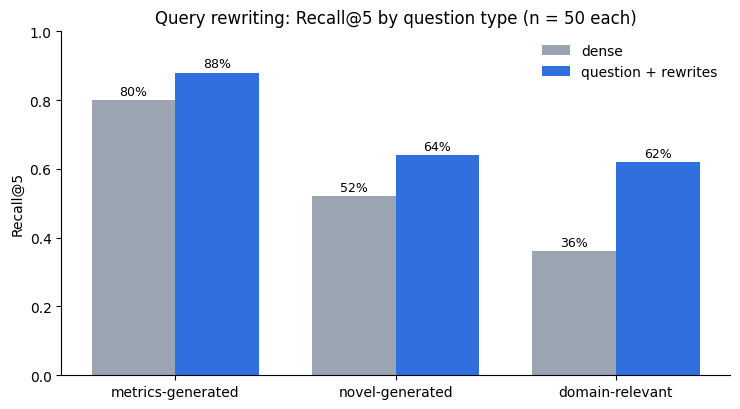

In [11]:
import matplotlib.pyplot as plt

out = summary.join(sig[['95% CI', 'gained vs dense', 'lost vs dense', 'McNemar p']])
out.to_csv(f'{ROOT}/rewrite_results.csv')
by_type.to_csv(f'{ROOT}/rewrite_results_by_type.csv')

# contexts for answer generation: top-5 chunks per question for the baseline and the extension
EXT_METHOD = 'question + rewrites'   # change if another rewrite method scored better above
contexts = {}
for _, q in qs.iterrows():
    contexts[q.financebench_id] = {
        tag: [{'page': int(chunks.at[i, 'page']), 'text': chunks.at[i, 'text']} for i in retrieved[m][q.financebench_id][:5]]
        for tag, m in (('dense', 'dense'), ('rewrite', EXT_METHOD))}
json.dump(contexts, open(f'{ROOT}/contexts.json', 'w'))
print('saved rewrite_results.csv, rewrite_results_by_type.csv, contexts.json to Drive')

# chart: recall@5 by question type, dense vs extension
types = ['metrics-generated', 'novel-generated', 'domain-relevant']
x = np.arange(len(types)); w = 0.38
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for j, (m, color) in enumerate((('dense', '#9AA5B1'), (EXT_METHOD, '#2F6FDE'))):
    vals = by_type.loc[m, types].values
    ax.bar(x + (j - 0.5) * w, vals, w, label=m, color=color)
    for xi, v in zip(x + (j - 0.5) * w, vals):
        ax.text(xi, v + 0.015, f'{v:.0%}', ha='center', fontsize=9)
ax.set_xticks(x, types)
ax.set_ylim(0, 1)
ax.set_ylabel('Recall@5')
ax.set_title('Query rewriting: Recall@5 by question type (n = 50 each)')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig(f'{ROOT}/rewrite_by_type.png', dpi=200)
plt.show()

## What to send back
1. The summary table (section 3) and the significance table (section 4)
2. The by-type table and the three McNemar lines (section 5)
3. The 3M example output (section 6)

Then run **Notebook 03b** (answer generation). It doesn't need a GPU, so switch the runtime back to CPU to save your GPU quota.